In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install torch lifelines -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 10.2 MB/s eta 0:00:00


In [3]:
import os
import json
import ast
import copy

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from lifelines.utils import concordance_index

In [4]:
PROCESSED_DATA_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/"
UNICOX_OUTPUT_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/UnivariateCox/"
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/"
MODEL_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/UnivariateCox/"

os.makedirs(UNICOX_OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

TRAIN_PATH = UNICOX_OUTPUT_DIR + "hcc_UniCox_train_selected.csv"

BEST_PARAMS_JSON_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_best_hyperparameters.json"
BEST_PARAMS_CSV_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_best_hyperparameters.csv"

MODEL_PATH = MODEL_DIR + "hcc_UniCox_deepsurv_model.pth"
TRAINING_SUMMARY_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_final_training_summary.csv"
LOSS_HISTORY_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_loss_history.csv"
LOSS_PLOT_PATH = RESULTS_DIR + "hcc_UniCox_deepsurv_training_loss.png"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"

In [5]:
train_data = pd.read_csv(TRAIN_PATH)

print("Train data shape:", train_data.shape)
train_data.head()

Train data shape: (1085, 52)


,METASTASIS_Yes,CURATIVE_INTENT_SURGERY_Yes,CURATIVE_INTENT_SURGERY_No,METASTASIS_No,MAJOR_LIVER_RESECTION_,RESECTION_MARGIN_,RESECTION_MARGIN_R0,C_N_Yes,PNI_,LVI_,...,TUMOR_STAGE_Poorly differentiated,TUMOR_STAGE_Well differentiated,MUT_SHQ1,CNA_XPO1,CNA_REL,MUT_KRAS,NEOADJUVANT_SYSTEMIC_THERAPY_No,MUT_FGFR4,OS_MONTHS,OS_EVENT
0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,82.296,0
1,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,51.324,1
2,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,6.600,1
3,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,24.480,0
4,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,14.592,1


In [6]:
print("Train missing values:", int(train_data.isna().sum().sum()))

print("\nTrain OS_EVENT distribution:")
print(train_data[EVENT_COL].value_counts())

Train missing values: 0

Train OS_EVENT distribution:
OS_EVENT
1    641
0    444
Name: count, dtype: int64


In [7]:
for id_col in ["PATIENT_ID", "SAMPLE_ID"]:
    assert id_col not in train_data.columns, f"{id_col} found in train_data"

print("ID leakage guard passed.")

ID leakage guard passed.


In [8]:
COLS_TO_DROP = []

if COLS_TO_DROP:
    train_data = train_data.drop(columns=COLS_TO_DROP)

train_data.shape

(1085, 52)

In [9]:
DEPENDENT_COLUMNS = ["OS_MONTHS", "OS_EVENT"]
ID_COLUMNS = ["PATIENT_ID", "SAMPLE_ID"]

GENES = [
    col for col in train_data.columns
    if col not in DEPENDENT_COLUMNS + ID_COLUMNS
]

print("Feature count:", len(GENES))
GENES[:10]

Feature count: 50


['METASTASIS_Yes',
 'CURATIVE_INTENT_SURGERY_Yes',
 'CURATIVE_INTENT_SURGERY_No',
 'METASTASIS_No',
 'MAJOR_LIVER_RESECTION_',
 'RESECTION_MARGIN_',
 'RESECTION_MARGIN_R0',
 'C_N_Yes',
 'PNI_',
 'LVI_']

In [10]:
X = train_data[GENES].copy()
y = train_data[DEPENDENT_COLUMNS].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1085, 50)
y shape: (1085, 2)


In [11]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RANDOM_STATE = 42

print("Device:", DEVICE)

Device: cpu


In [12]:
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_STATE)

In [13]:
best_params_df = pd.read_csv(BEST_PARAMS_CSV_PATH)
best_params_df

,hidden_layers,dropout_rate,batch_size,activation,optimizer,weight_decay,learning_rate,patience,epochs,mean_best_epoch,mean_c_index
0,"[128, 64]",0.2,128,ReLU,Adam,0.0001,0.005,20,75,32.4,0.746464


In [14]:
best_row = best_params_df.iloc[0].copy()

BEST_HIDDEN_LAYERS = ast.literal_eval(best_row["hidden_layers"])
BEST_DROPOUT_RATE = float(best_row["dropout_rate"])
BEST_BATCH_SIZE = int(best_row["batch_size"])
BEST_ACTIVATION = str(best_row["activation"])
BEST_OPTIMIZER = str(best_row["optimizer"])
BEST_WEIGHT_DECAY = float(best_row["weight_decay"])
BEST_LEARNING_RATE = float(best_row["learning_rate"])
BEST_PATIENCE = int(best_row["patience"])
BEST_EPOCHS = int(best_row["epochs"])
BEST_MEAN_BEST_EPOCH = float(best_row["mean_best_epoch"])
BEST_MEAN_C_INDEX = float(best_row["mean_c_index"])

print("Best hidden layers:", BEST_HIDDEN_LAYERS)
print("Best dropout rate:", BEST_DROPOUT_RATE)
print("Best batch size:", BEST_BATCH_SIZE)
print("Best activation:", BEST_ACTIVATION)
print("Best optimizer:", BEST_OPTIMIZER)
print("Best weight decay:", BEST_WEIGHT_DECAY)
print("Best learning rate:", BEST_LEARNING_RATE)
print("Best patience:", BEST_PATIENCE)
print("Best epochs:", BEST_EPOCHS)
print("Best mean validation C-index:", round(BEST_MEAN_C_INDEX, 4))

Best hidden layers: [128, 64]
Best dropout rate: 0.2
Best batch size: 128
Best activation: ReLU
Best optimizer: Adam
Best weight decay: 0.0001
Best learning rate: 0.005
Best patience: 20
Best epochs: 75
Best mean validation C-index: 0.7465


In [15]:
class DeepSurv(nn.Module):
    def __init__(self, input_dim, hidden_layers, dropout_rate, activation_name):
        super(DeepSurv, self).__init__()

        activation_map = {
            "ReLU": nn.ReLU,
            "LeakyReLU": nn.LeakyReLU,
            "ELU": nn.ELU,
            "SELU": nn.SELU
        }

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(activation_map[activation_name]())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            current_dim = hidden_dim

        self.feature_extractor = nn.Sequential(*layers)
        self.output_layer = nn.Linear(current_dim, 1)

    def forward(self, x):
        x = self.feature_extractor(x)
        return self.output_layer(x)

In [16]:
def nll_loss(preds, durations, events):
    order = torch.argsort(durations, descending=True)

    hazards = preds[order].reshape(-1)
    events = events[order].reshape(-1)

    log_risk = torch.logcumsumexp(hazards, dim=0)
    uncensored_loss = hazards - log_risk
    censored_loss = uncensored_loss * events

    return -torch.sum(censored_loss) / torch.sum(events)

In [17]:
def build_optimizer(model, optimizer_name, learning_rate, weight_decay):
    if optimizer_name == "Adam":
        return optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == "AdamW":
        return optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == "RMSprop":
        return optim.RMSprop(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")

In [18]:
X_train_tensor = torch.tensor(X.values, dtype=torch.float32)
y_train_duration = torch.tensor(y[DURATION_COL].values, dtype=torch.float32)
y_train_event = torch.tensor(y[EVENT_COL].values, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_duration, y_train_event)
train_loader = DataLoader(
    train_dataset,
    batch_size=BEST_BATCH_SIZE,
    shuffle=True
)

print("Training tensor shape:", X_train_tensor.shape)
print("Batch size:", BEST_BATCH_SIZE)

Training tensor shape: torch.Size([1085, 50])
Batch size: 128


In [19]:
input_dim = X.shape[1]

model = DeepSurv(
    input_dim=input_dim,
    hidden_layers=BEST_HIDDEN_LAYERS,
    dropout_rate=BEST_DROPOUT_RATE,
    activation_name=BEST_ACTIVATION
).to(DEVICE)

optimizer = build_optimizer(
    model=model,
    optimizer_name=BEST_OPTIMIZER,
    learning_rate=BEST_LEARNING_RATE,
    weight_decay=BEST_WEIGHT_DECAY
)

In [20]:
loss_history = []

for epoch in range(BEST_EPOCHS):
    model.train()
    epoch_losses = []

    for batch_X, batch_duration, batch_event in train_loader:
        batch_X = batch_X.to(DEVICE)
        batch_duration = batch_duration.to(DEVICE)
        batch_event = batch_event.to(DEVICE)

        optimizer.zero_grad()
        preds = model(batch_X)
        loss = nll_loss(preds, batch_duration, batch_event)
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())

    mean_epoch_loss = np.mean(epoch_losses)
    loss_history.append(mean_epoch_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{BEST_EPOCHS} - Loss: {mean_epoch_loss:.4f}")

Epoch 1/75 - Loss: 3.8811
Epoch 10/75 - Loss: 3.6099
Epoch 20/75 - Loss: 3.5925
Epoch 30/75 - Loss: 3.5442
Epoch 40/75 - Loss: 3.5266
Epoch 50/75 - Loss: 3.5333
Epoch 60/75 - Loss: 3.5109
Epoch 70/75 - Loss: 3.4924


In [21]:
model.eval()

X_all_tensor = torch.tensor(X.values, dtype=torch.float32).to(DEVICE)

with torch.no_grad():
    train_preds = model(X_all_tensor).cpu().numpy().reshape(-1)

train_c_index = concordance_index(
    y[DURATION_COL].values,
    -train_preds,
    y[EVENT_COL].values
)

print(f"Training Concordance Index: {train_c_index:.4f}")

Training Concordance Index: 0.7806


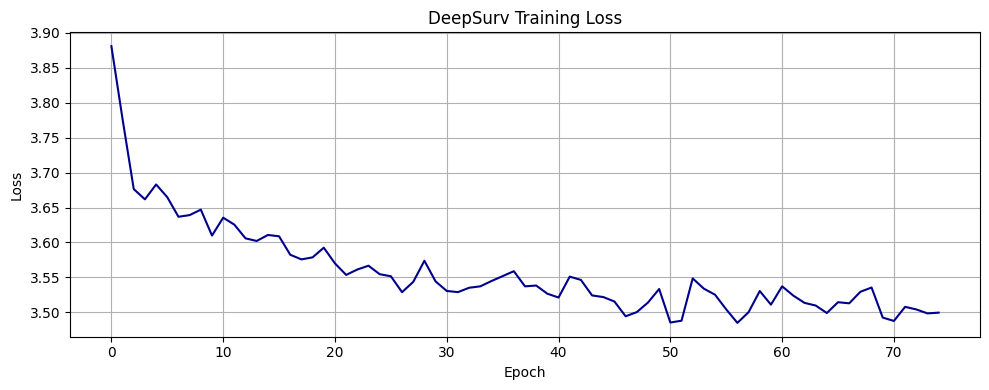

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_training_loss.png'

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(loss_history, color="darkblue")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DeepSurv Training Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

LOSS_PLOT_PATH

In [23]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "input_dim": input_dim,
    "hidden_layers": BEST_HIDDEN_LAYERS,
    "dropout_rate": BEST_DROPOUT_RATE,
    "batch_size": BEST_BATCH_SIZE,
    "activation": BEST_ACTIVATION,
    "optimizer": BEST_OPTIMIZER,
    "weight_decay": BEST_WEIGHT_DECAY,
    "learning_rate": BEST_LEARNING_RATE,
    "patience": BEST_PATIENCE,
    "epochs": BEST_EPOCHS,
    "mean_best_epoch": BEST_MEAN_BEST_EPOCH,
    "mean_c_index": BEST_MEAN_C_INDEX,
    "feature_columns": GENES,
    "duration_col": DURATION_COL,
    "event_col": EVENT_COL
}

torch.save(checkpoint, MODEL_PATH)

print("Model saved to:", MODEL_PATH)

Model saved to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/UnivariateCox/hcc_UniCox_deepsurv_model.pth


In [24]:
loss_history_df = pd.DataFrame({
    "epoch": np.arange(1, len(loss_history) + 1),
    "loss": loss_history
})

loss_history_df.to_csv(LOSS_HISTORY_PATH, index=False)

LOSS_HISTORY_PATH

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_loss_history.csv'

In [25]:
training_summary_df = pd.DataFrame([{
    "hidden_layers": json.dumps(BEST_HIDDEN_LAYERS),
    "dropout_rate": BEST_DROPOUT_RATE,
    "batch_size": BEST_BATCH_SIZE,
    "activation": BEST_ACTIVATION,
    "optimizer": BEST_OPTIMIZER,
    "weight_decay": BEST_WEIGHT_DECAY,
    "learning_rate": BEST_LEARNING_RATE,
    "patience": BEST_PATIENCE,
    "epochs": BEST_EPOCHS,
    "mean_best_epoch": BEST_MEAN_BEST_EPOCH,
    "mean_validation_c_index": BEST_MEAN_C_INDEX,
    "training_c_index": train_c_index,
    "model_path": MODEL_PATH
}])

training_summary_df.to_csv(TRAINING_SUMMARY_PATH, index=False)

training_summary_df

,hidden_layers,dropout_rate,batch_size,activation,optimizer,weight_decay,learning_rate,patience,epochs,mean_best_epoch,mean_validation_c_index,training_c_index,model_path
0,"[128, 64]",0.2,128,ReLU,Adam,0.0001,0.005,20,75,32.4,0.746464,0.780571,/content/drive/MyDrive/IEEE Project/Hepatocell...


In [26]:
MODEL_PATH, TRAINING_SUMMARY_PATH

('/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/UnivariateCox/hcc_UniCox_deepsurv_model.pth',
 '/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/UnivariateCox/hcc_UniCox_deepsurv_final_training_summary.csv')

**UnivariateCox DeepSurv Final Model Saving Summary**

The saving-best-model notebook has now been completed for the updated UnivariateCox DeepSurv experiment. This notebook used the best hyperparameters identified during cross-validation and retrained one final DeepSurv model on the full UnivariateCox training dataset.

This is the final model artifact that will be used for held-out test evaluation and later DeepSurv XAI interpretation.

**Best Hyperparameters Used**

| Hyperparameter | Final Value |
|---|---|
| Hidden layers | `[128, 64]` |
| Dropout rate | `0.2` |
| Batch size | `128` |
| Activation | `ReLU` |
| Optimizer | `Adam` |
| Weight decay | `0.0001` |
| Learning rate | `0.005` |
| Early stopping patience | `20` |
| Maximum epochs | `75` |
| Mean best epoch from CV | `32.4` |
| Mean validation C-index from CV | `0.7465` |

The model selected from tuning was a two-hidden-layer DeepSurv network. The first hidden layer had 128 neurons and the second had 64 neurons. Dropout of `0.2` and L2-style weight decay of `0.0001` were used for regularization.

**Training Process**

After loading the best hyperparameters, the notebook retrained the DeepSurv model on the full UnivariateCox training dataset. The model optimized the Cox partial likelihood loss, which is appropriate for right-censored survival data.

The loss decreased over training:

| Epoch | Loss |
|---|---:|
| 1 | `3.8811` |
| 10 | `3.6099` |
| 20 | `3.5925` |
| 30 | `3.5442` |
| 40 | `3.5266` |
| 50 | `3.5333` |
| 60 | `3.5109` |
| 70 | `3.4924` |

The overall trend is downward, showing that the model learned useful survival-risk structure from the selected features. There is some fluctuation after epoch 40, which is normal for mini-batch neural-network training, especially with dropout enabled.

**Training Concordance**

The final model achieved:

| Metric | Value |
|---|---:|
| Mean validation C-index from CV | `0.7465` |
| Final training C-index | `0.7806` |

The training C-index of `0.7806` means that, on the full training data, the final DeepSurv model correctly ranked survival risk for about 78.1% of comparable patient pairs.

This is higher than the cross-validation mean C-index of `0.7465`, which is expected because the final model is evaluated on the same data it was trained on. The key number for model selection remains the cross-validated validation C-index, and the final judgment will come from the held-out test evaluation.

**Generalization Signal**

The gap between validation and training C-index is:

| Comparison | Value |
|---|---:|
| Training C-index | `0.7806` |
| Mean validation C-index | `0.7465` |
| Difference | `0.0341` |

This suggests the model has some expected training advantage, but the gap is not extreme. The presence of dropout and weight decay likely helped control overfitting. However, the held-out test set is still required to determine true generalization.

**Why This Model Is Important**

This final saved DeepSurv model is important because it represents the optimized nonlinear survival model for the updated UnivariateCox feature set. Compared with CoxPH, DeepSurv can capture nonlinear relationships and feature interactions among clinical, mutation, and CNA predictors.

The final model combines:

| Component | Role |
|---|---|
| UnivariateCox-selected features | Statistically survival-associated input variables |
| DeepSurv architecture | Nonlinear survival-risk modeling |
| Cox partial likelihood loss | Handles censored survival outcomes |
| Dropout and weight decay | Improve regularization |
| Cross-validated hyperparameter tuning | Reduces arbitrary model configuration |
| Saved model checkpoint | Enables reproducibility and XAI |

**Saved Output**

The notebook saved the final model and training summary. The summary table contains:

| Field | Meaning |
|---|---|
| `hidden_layers` | Final neural architecture |
| `dropout_rate` | Dropout regularization |
| `batch_size` | Training batch size |
| `activation` | Neural activation function |
| `optimizer` | Optimization algorithm |
| `weight_decay` | L2-style regularization |
| `learning_rate` | Step size for optimization |
| `patience` | Early stopping patience from tuning |
| `epochs` | Maximum training epochs |
| `mean_best_epoch` | Average best epoch during CV |
| `mean_validation_c_index` | Cross-validation model-selection score |
| `training_c_index` | Final model performance on full training data |
| `model_path` | Location of saved `.pth` model file |

**Key Takeaways**

The updated UnivariateCox DeepSurv final model was successfully trained and saved.

The best model used `[128, 64]` hidden layers with dropout `0.2`, ReLU activation, Adam optimizer, learning rate `0.005`, and weight decay `0.0001`.

The model reached a strong training C-index of `0.7806`.

The cross-validation C-index was `0.7465`, which is the more reliable training-stage performance estimate.

The training loss decreased steadily from `3.8811` to approximately `3.49`, indicating effective learning.

The model is now ready for held-out test evaluation and later DeepSurv XAI analysis.

**Conclusion**

This notebook completed the final model-saving stage for the updated UnivariateCox DeepSurv workflow. The model was trained using the best cross-validated hyperparameters and saved for reproducibility. The training results indicate that the nonlinear DeepSurv model learned a strong survival-risk representation from the revised UnivariateCox-selected feature set. The next critical step is to evaluate this saved model on the held-out test set to confirm whether the improved validation performance translates into stronger test-set survival prediction.